In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
np.random.seed(42)
X=np.random.rand(100,1)-0.5
y=3*X[:,0]**2 +0.05*np.random.randn(100)

In [6]:
X.shape

(100, 1)

In [4]:
df = pd.DataFrame()

In [5]:
df['X'] = X.reshape(100)

In [7]:
y.shape

(100,)

In [8]:
df['y']=y

In [9]:
df.head(5)

,X,y
0,-0.125460,0.051573
1,0.450714,0.594480
2,0.231994,0.166052
3,0.098658,-0.070178
4,-0.343981,0.343986


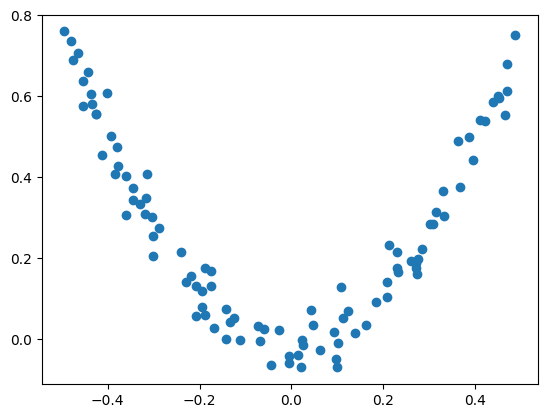

In [10]:
plt.scatter(X,y)

In [11]:
df['pred1'] = df['y'].mean()

In [12]:
df.head(2)

,X,y,pred1
0,-0.125460,0.051573,0.265458
1,0.450714,0.594480,0.265458


In [13]:
df['res1']= df['y']-df['pred1']

In [14]:
df.head(2)

,X,y,pred1,res1
0,-0.125460,0.051573,0.265458,-0.213885
1,0.450714,0.594480,0.265458,0.329021


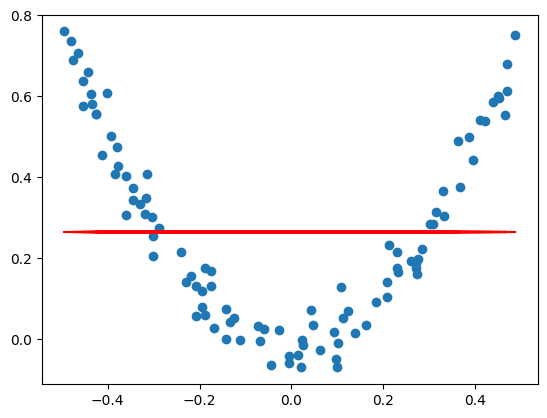

In [16]:
plt.scatter(X,y)
plt.plot(df['X'], df['pred1'], color='red')

In [17]:
from sklearn.tree import DecisionTreeRegressor

In [18]:
tree1 = DecisionTreeRegressor(max_leaf_nodes=8)

In [21]:
df['X'].shape

(100,)

In [22]:
df['res1'].shape

(100,)

In [20]:
tree1.fit(df['X'].values.reshape(100,1),df['res1'].values)

DecisionTreeRegressor(max_leaf_nodes=8)

[Text(0.4090909090909091, 0.9166666666666666, 'x[0] <= -0.36\nsquared_error = 0.056\nsamples = 100\nvalue = 0.0'),
 Text(0.18181818181818182, 0.75, 'x[0] <= -0.43\nsquared_error = 0.012\nsamples = 18\nvalue = 0.309'),
 Text(0.29545454545454547, 0.8333333333333333, 'True  '),
 Text(0.09090909090909091, 0.5833333333333334, 'squared_error = 0.004\nsamples = 9\nvalue = 0.395'),
 Text(0.2727272727272727, 0.5833333333333334, 'squared_error = 0.005\nsamples = 9\nvalue = 0.222'),
 Text(0.6363636363636364, 0.75, 'x[0] <= 0.322\nsquared_error = 0.04\nsamples = 82\nvalue = -0.068'),
 Text(0.5227272727272727, 0.8333333333333333, '  False'),
 Text(0.45454545454545453, 0.5833333333333334, 'x[0] <= -0.235\nsquared_error = 0.016\nsamples = 67\nvalue = -0.142'),
 Text(0.36363636363636365, 0.4166666666666667, 'squared_error = 0.003\nsamples = 12\nvalue = 0.041'),
 Text(0.5454545454545454, 0.4166666666666667, 'x[0] <= 0.211\nsquared_error = 0.009\nsamples = 55\nvalue = -0.182'),
 Text(0.45454545454545453

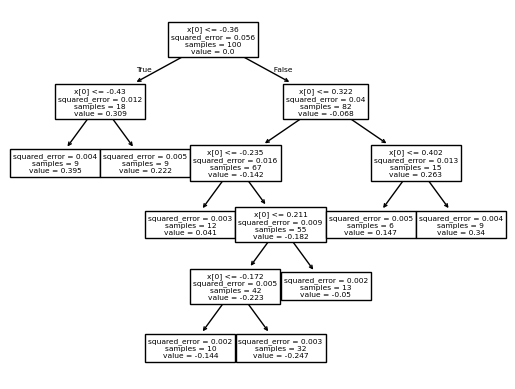

In [23]:
from sklearn.tree import plot_tree
plot_tree(tree1)

In [24]:
X_test = np.linspace(-0.5, 0.5, 500)

In [25]:
y_pred = 0.265458 + tree1.predict(X_test.reshape(500,1)) 

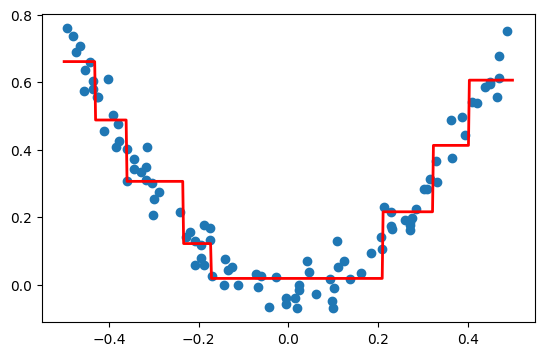

In [27]:
plt.figure(figsize=(14,4))
plt.subplot(121)
plt.plot(X_test,y_pred,linewidth=2,color='red')
plt.scatter(X,y)

In [28]:
df.head(3)

,X,y,pred1,res1
0,-0.125460,0.051573,0.265458,-0.213885
1,0.450714,0.594480,0.265458,0.329021
2,0.231994,0.166052,0.265458,-0.099407


In [30]:
df['pred2']= 0.265458 +tree1.predict(df['X'].values.reshape(100,1))

In [31]:
df.head(2)

,X,y,pred1,res1,pred2
0,-0.125460,0.051573,0.265458,-0.213885,0.018319
1,0.450714,0.594480,0.265458,0.329021,0.605884


In [32]:
df['res2'] =df['y']-df['pred2']

In [33]:
df.head(2)

,X,y,pred1,res1,pred2,res2
0,-0.125460,0.051573,0.265458,-0.213885,0.018319,0.033254
1,0.450714,0.594480,0.265458,0.329021,0.605884,-0.011404


In [34]:
tree2 = DecisionTreeRegressor(max_leaf_nodes=8)

In [35]:
tree2.fit(df['X'].values.reshape(100,1),df['res2'].values)

DecisionTreeRegressor(max_leaf_nodes=8)

In [36]:
y_pred=0.26548 + sum(regressor.predict(X_test.reshape(-1,1)) for regressor in [tree1,tree2])

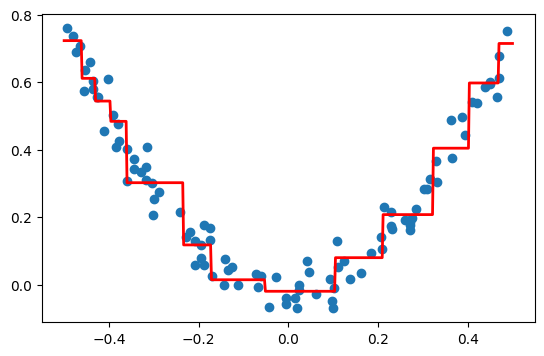

In [37]:
plt.figure(figsize=(14,4))
plt.subplot(121)
plt.plot(X_test,y_pred,linewidth=2,color='red')
plt.scatter(X,y)

In [40]:
def gradient_boost(X,y,number,lr,count=1,regs=[],foo=None):

  if number == 0:
    return 
  else:
    # do gradient boosting

    if count > 1:
      y = y - regs[-1].predict(X)
    else:
      foo = y

    tree_reg = DecisionTreeRegressor(max_depth=5, random_state=42)
    tree_reg.fit(X, y)

    regs.append(tree_reg)

    x1 = np.linspace(-0.5, 0.5, 500)
    y_pred = sum(lr * regressor.predict(x1.reshape(-1, 1)) for regressor in regs)

    print(number)
    plt.figure()
    plt.plot(x1, y_pred, linewidth=2)
    plt.plot(X[:, 0], foo,"r.")
    plt.show()

    gradient_boost(X,y,number-1,lr,count+1,regs,foo=foo)

     

In [41]:
np.random.seed(42)

5


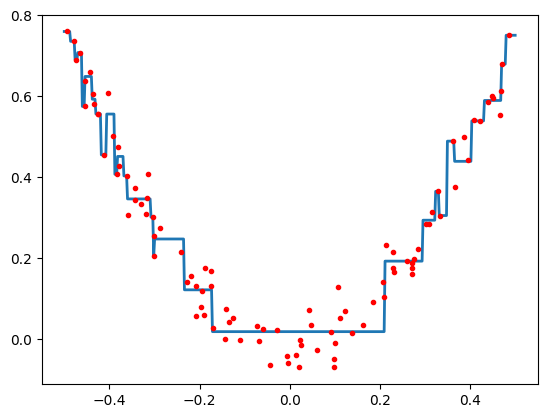

4


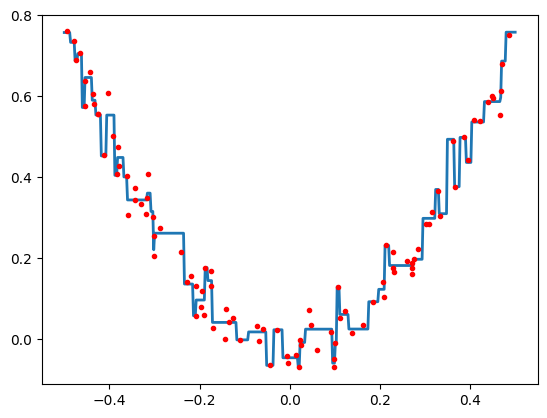

3


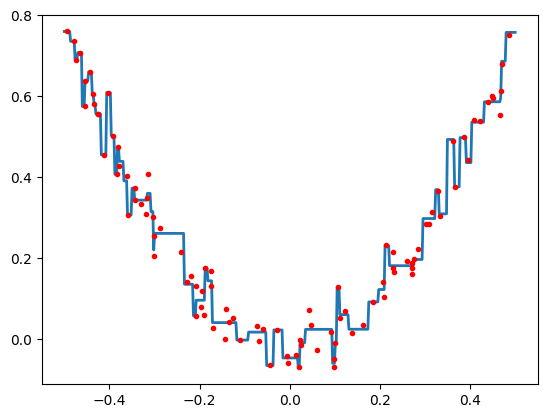

2


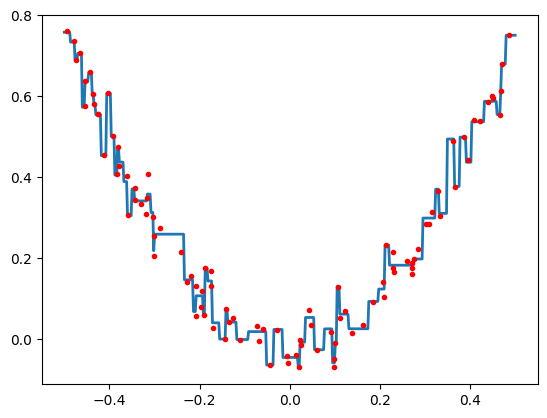

1


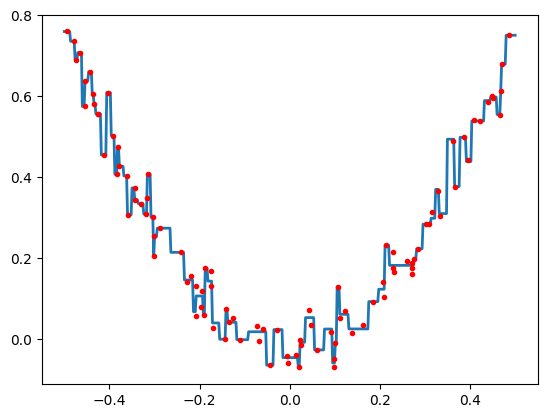

In [42]:
X = np.random.rand(100,1) - 0.5
y = 3*X[:,0]**2+0.05*np.random.randn(100)
gradient_boost(X,y,5,lr=1)

10


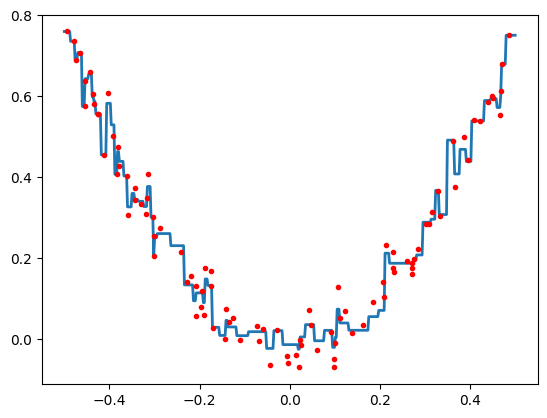

9


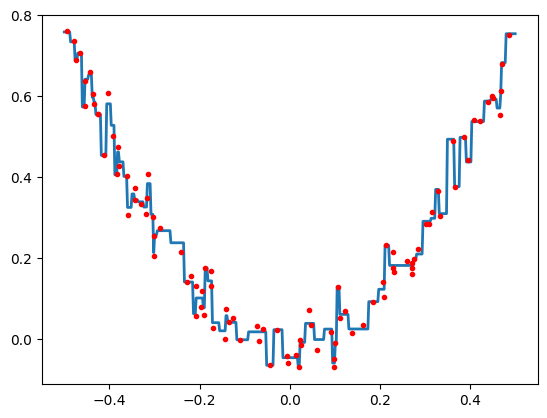

8


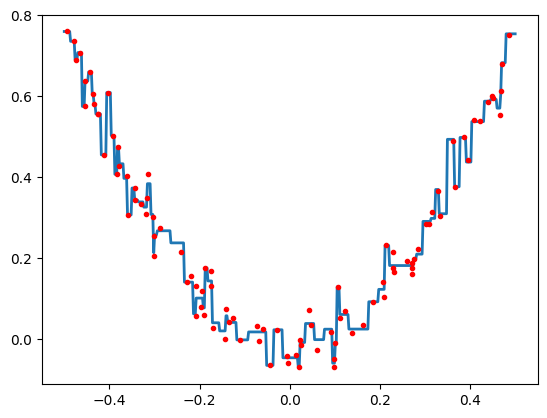

7


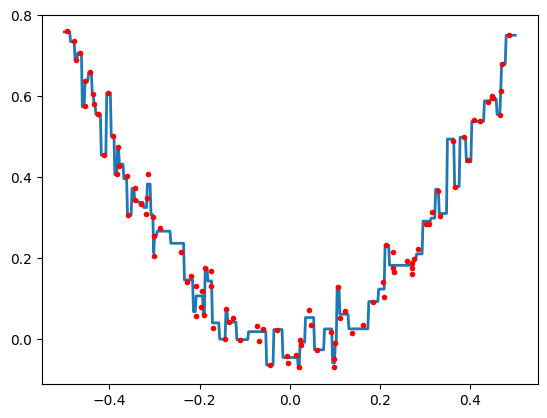

6


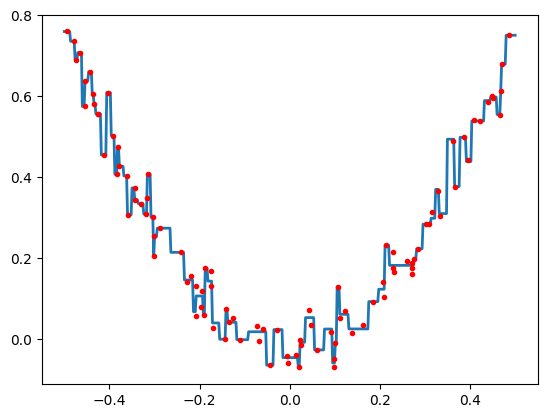

5


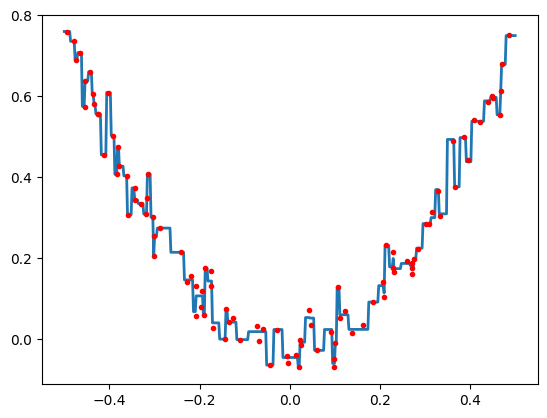

4


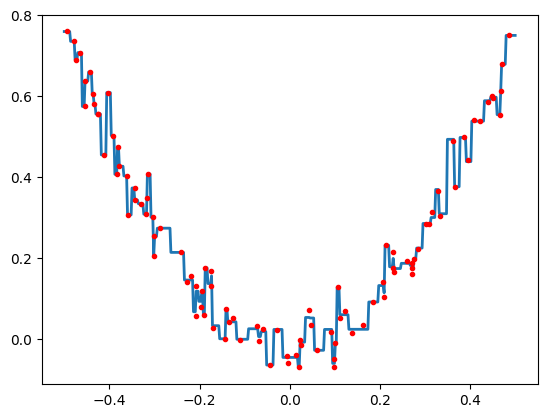

3


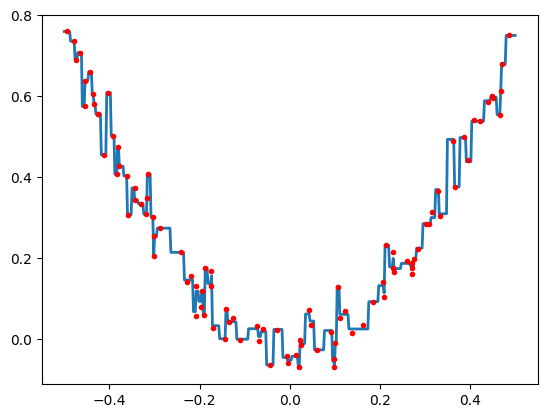

2


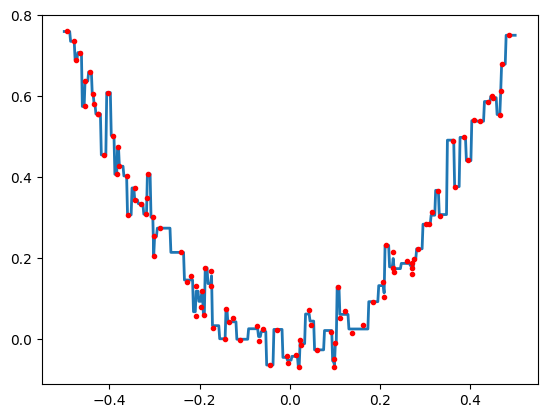

1


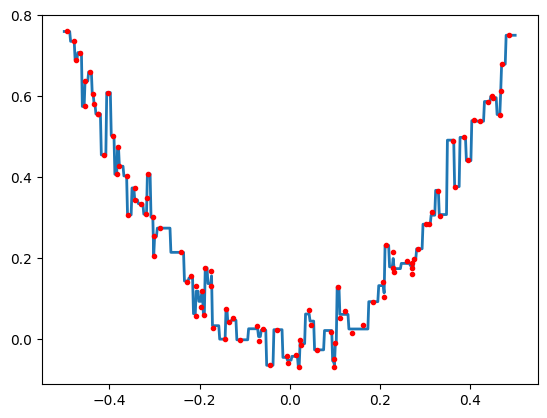

In [43]:
gradient_boost(X,y,10,lr=0.5)

100


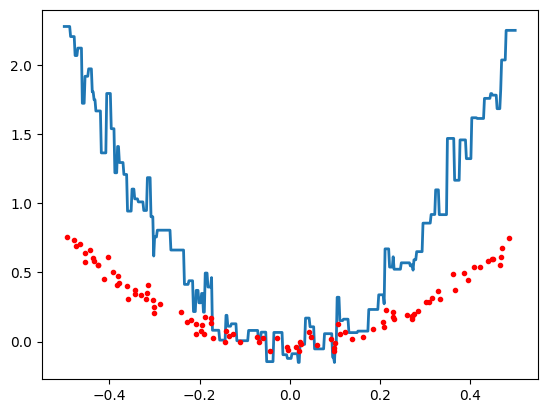

99


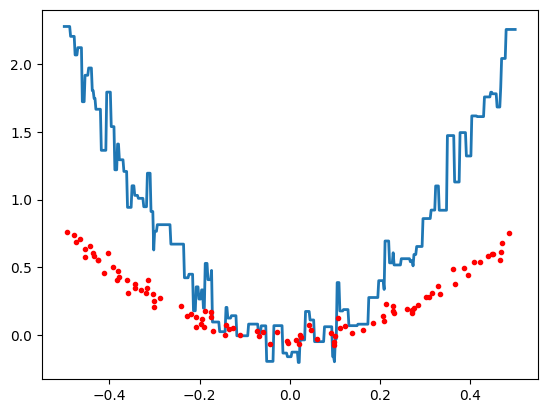

98


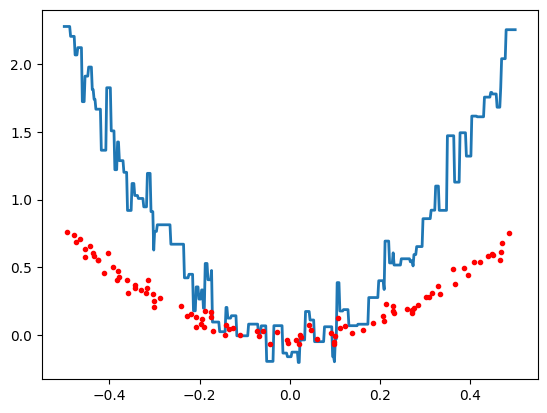

97


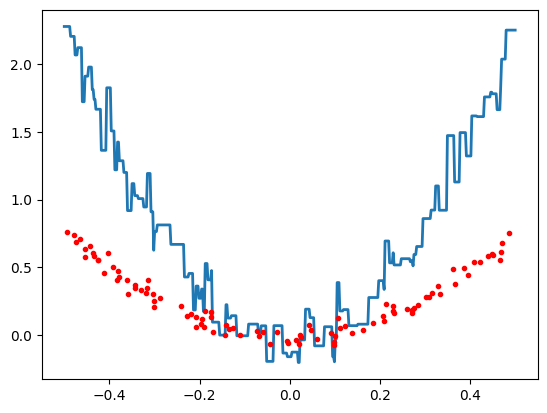

96


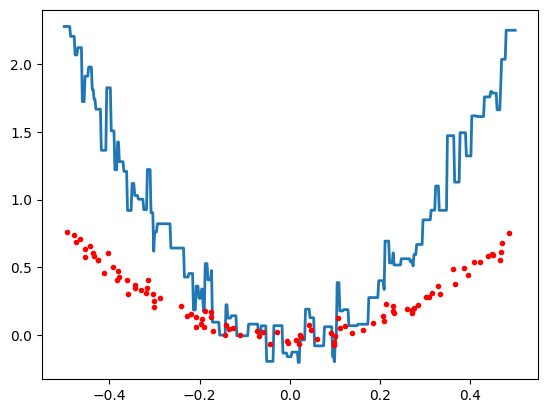

95


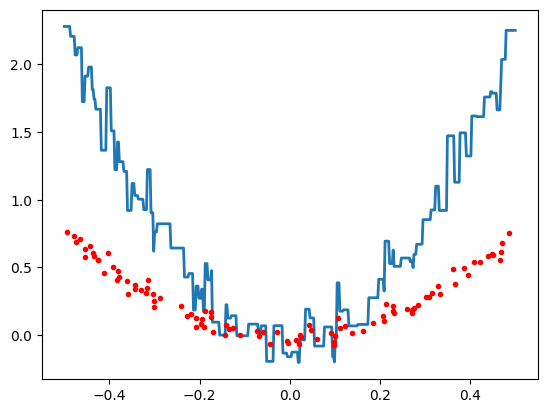

94


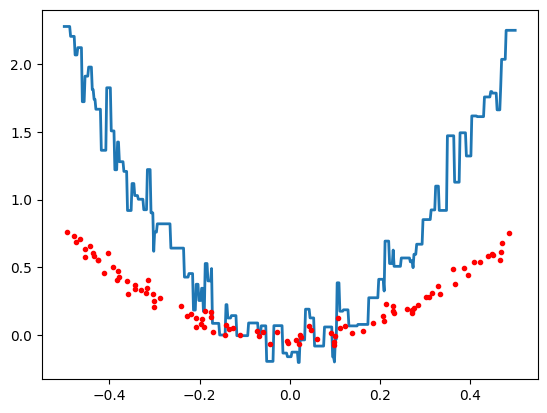

93


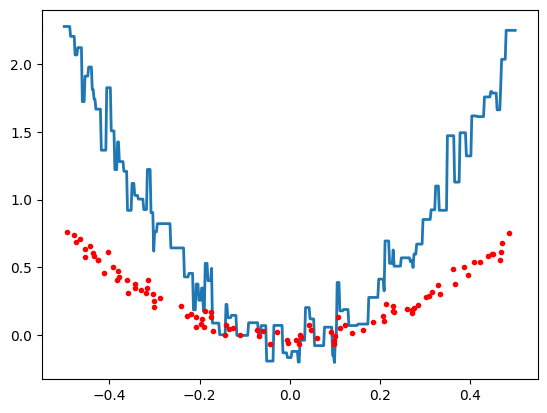

92


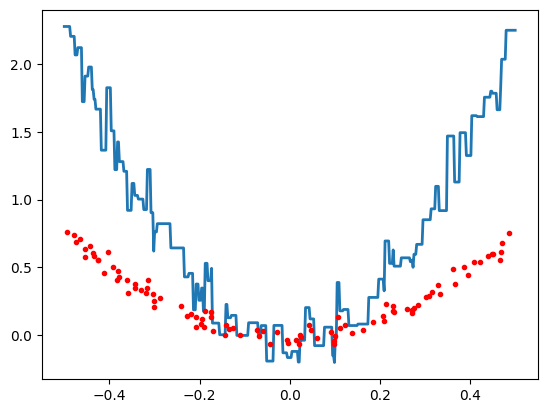

91


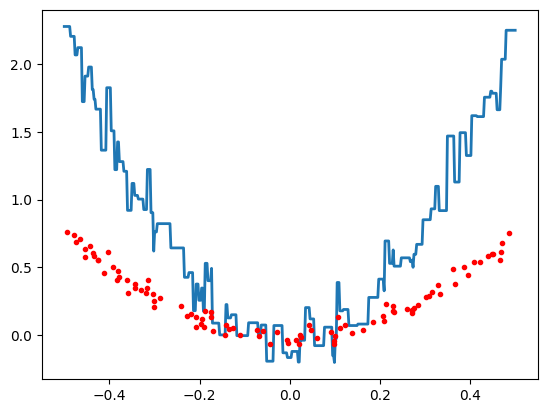

90


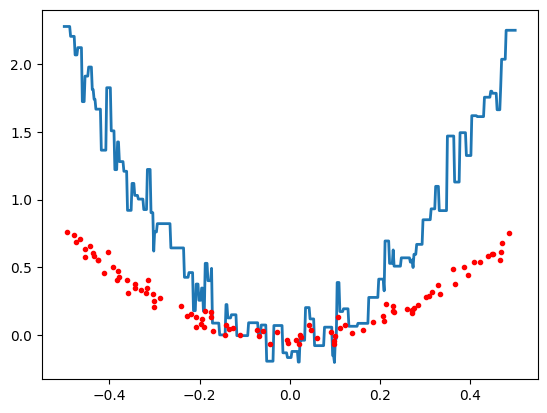

89


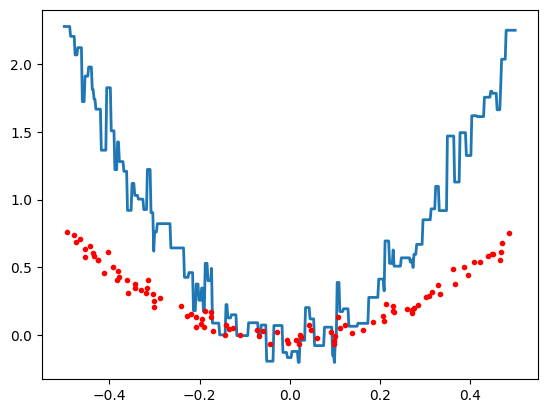

88


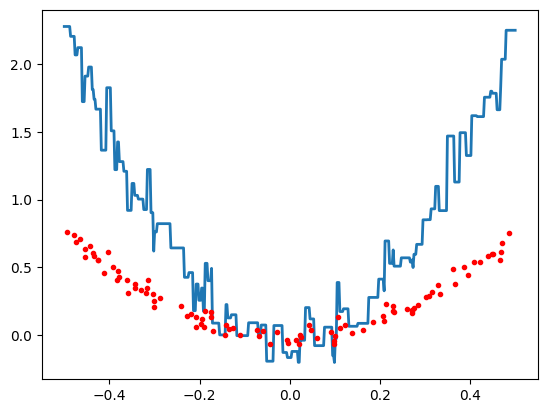

87


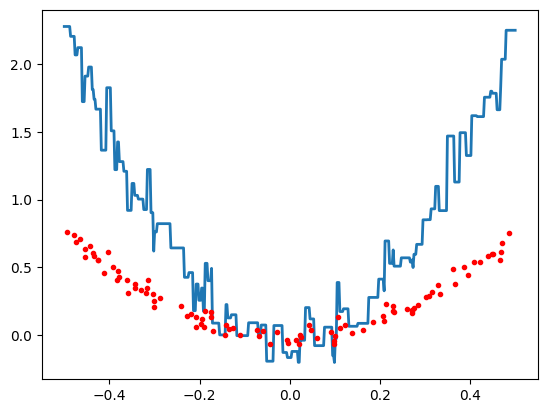

86


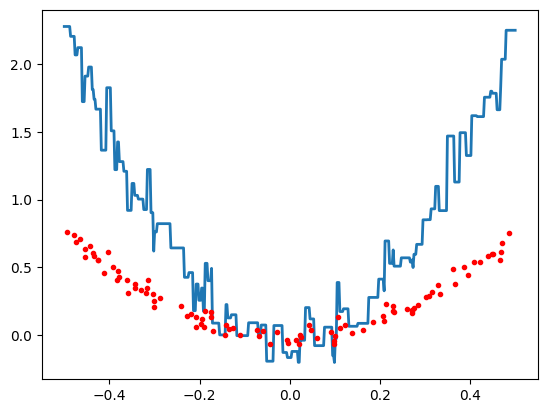

85


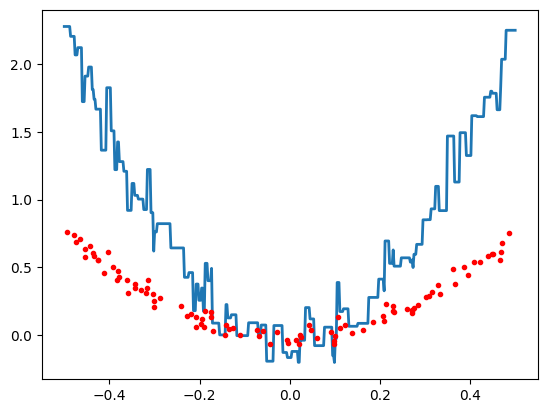

84


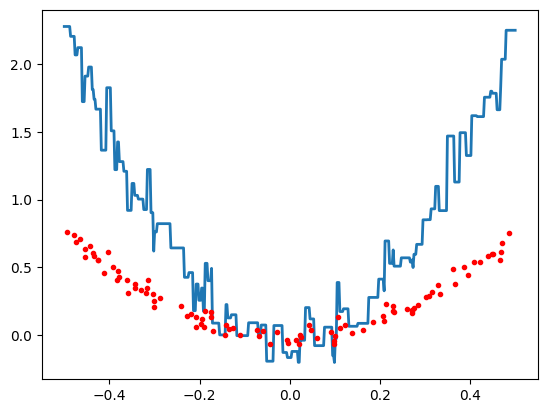

83


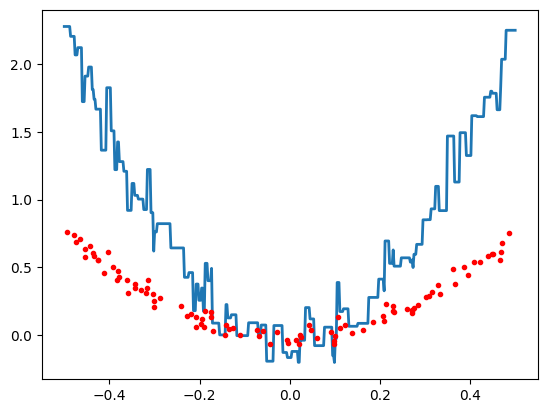

82


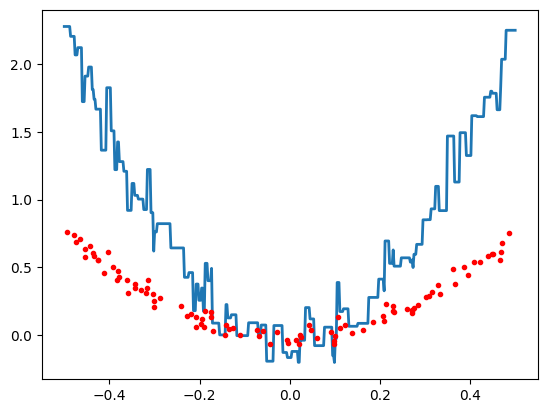

81


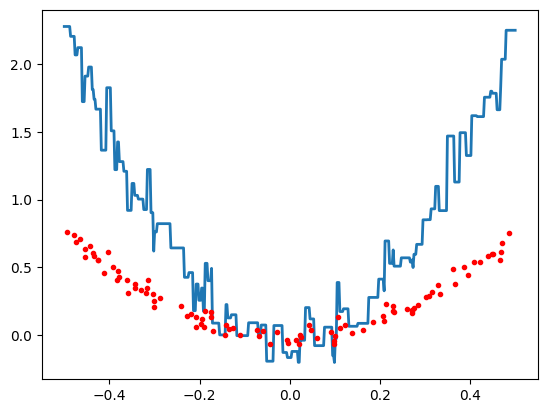

80


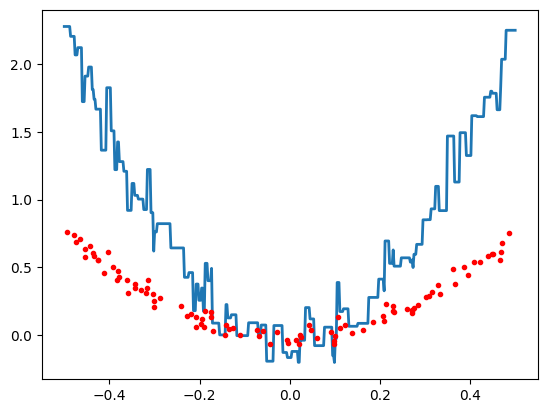

79


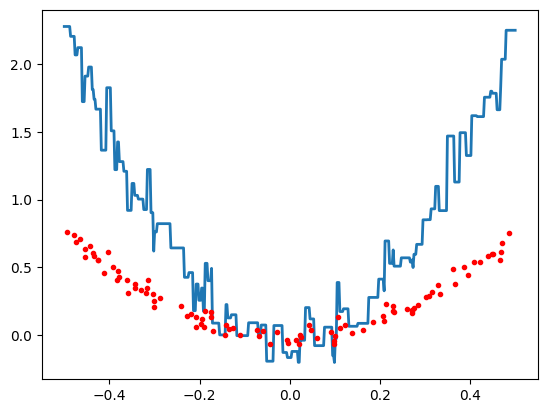

78


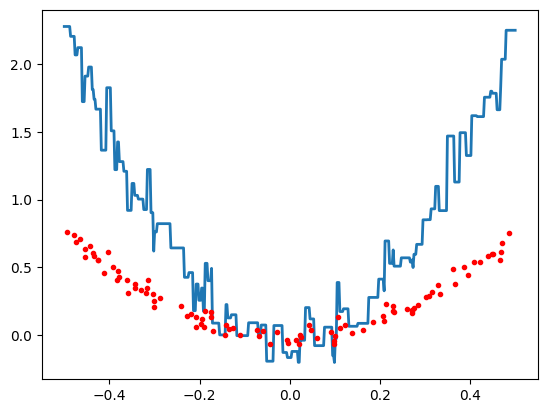

77


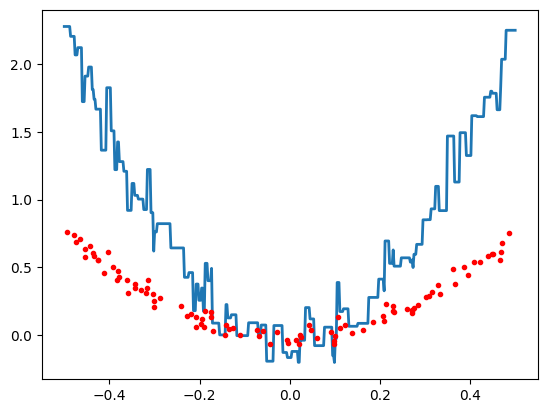

76


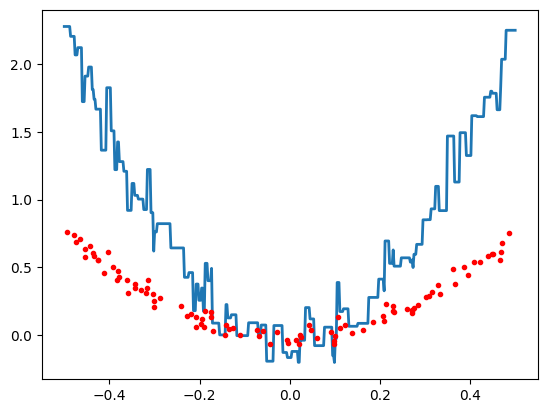

75


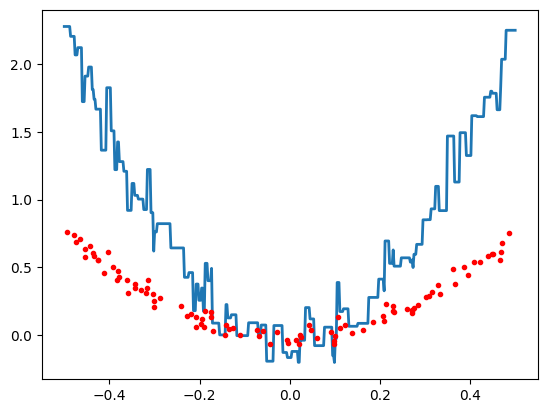

74


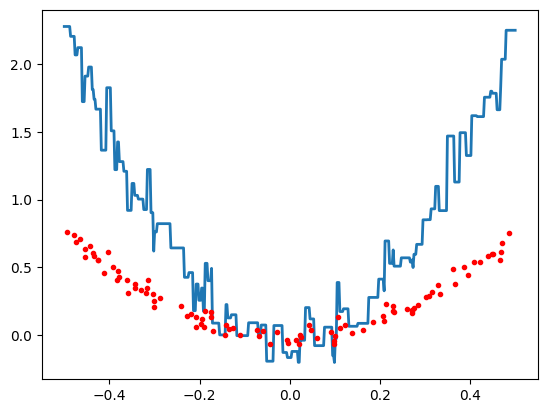

73


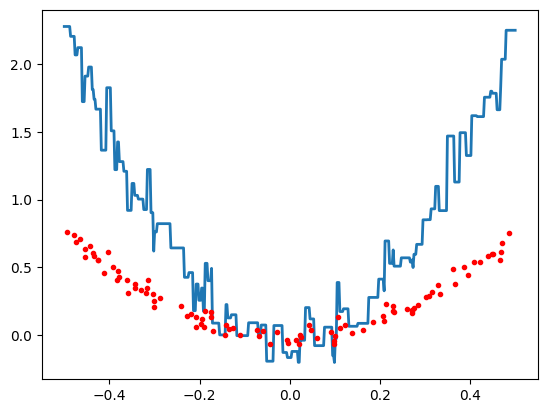

72


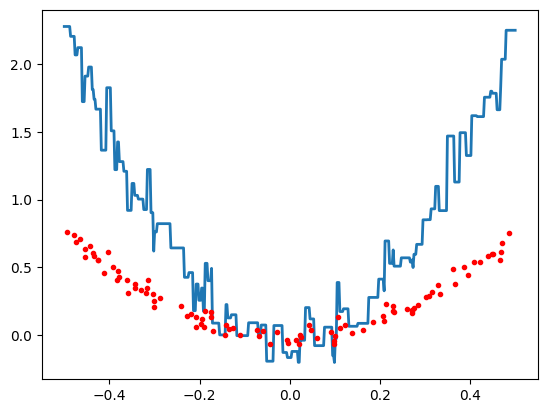

71


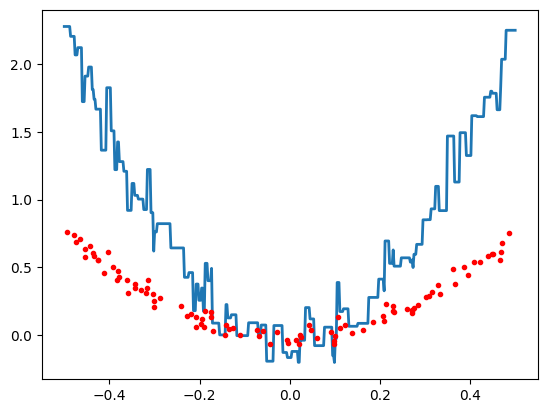

70


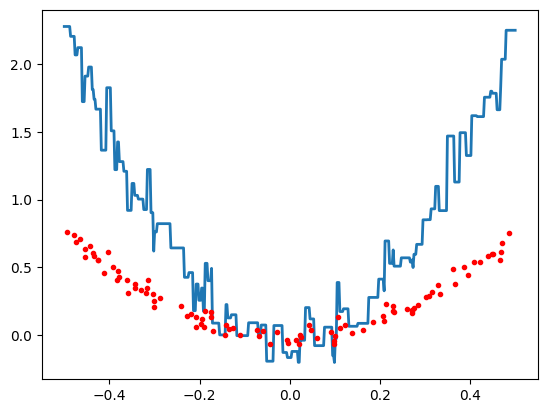

69


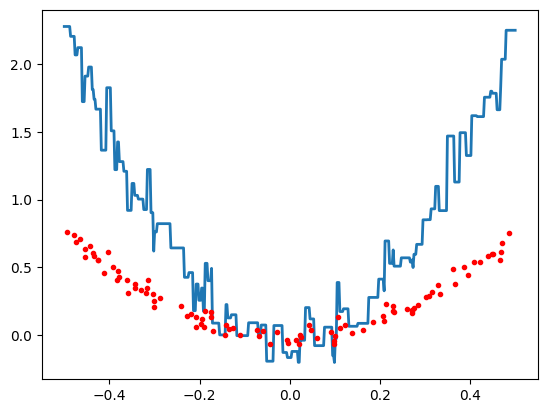

68


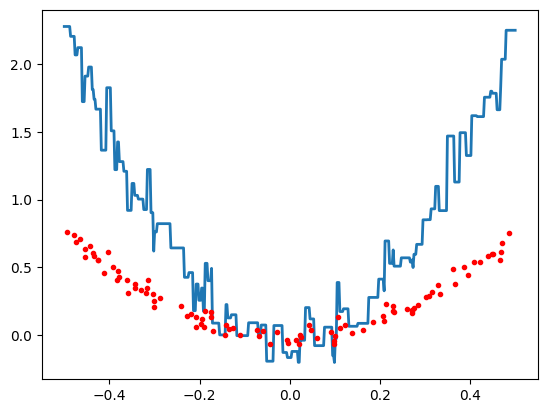

67


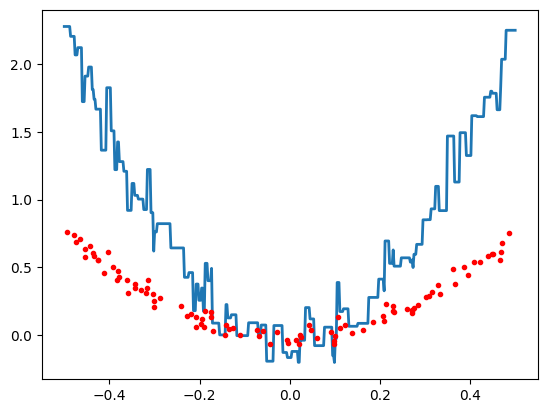

66


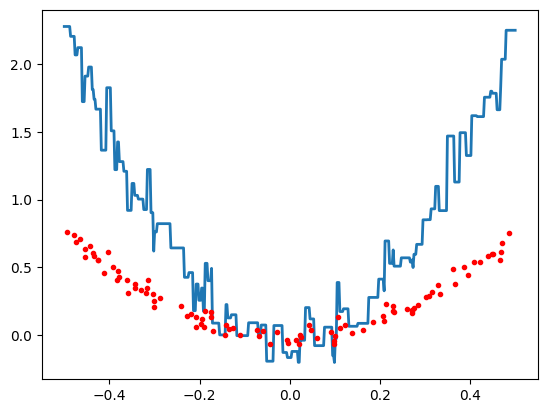

65


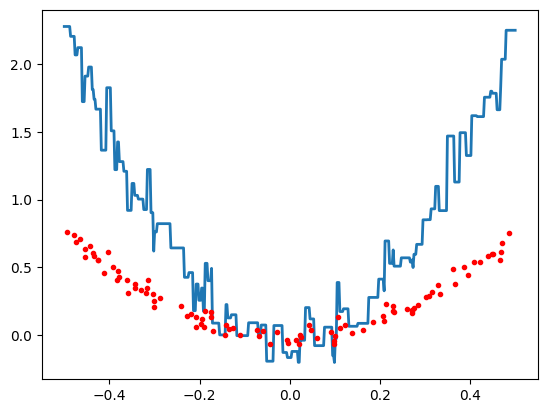

64


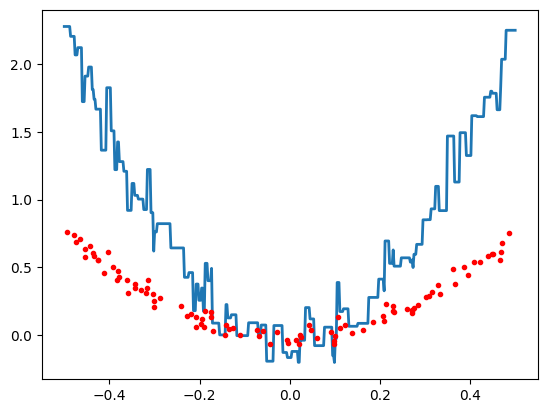

63


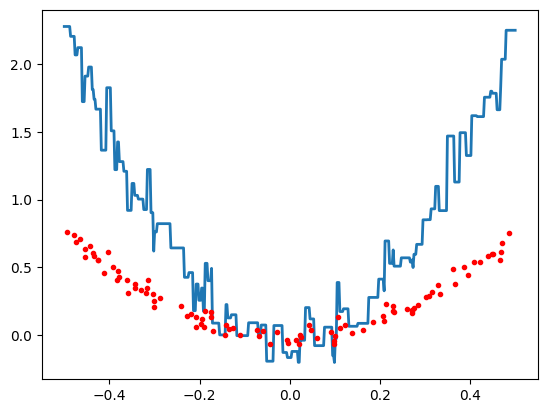

62


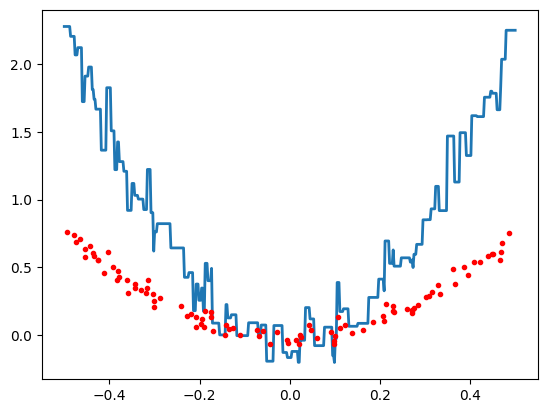

61


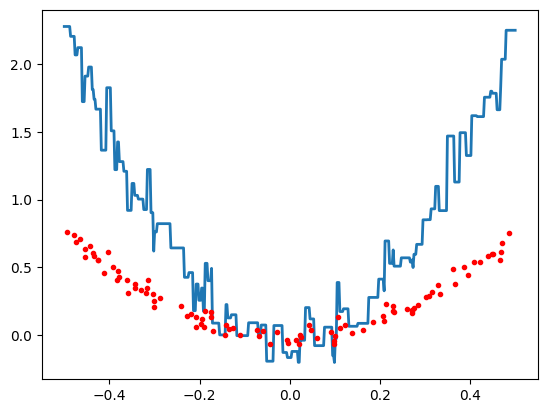

60


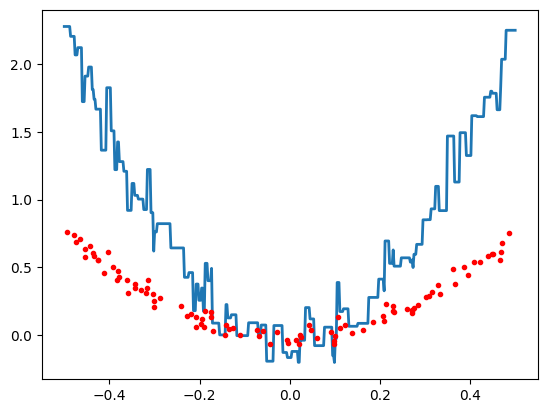

59


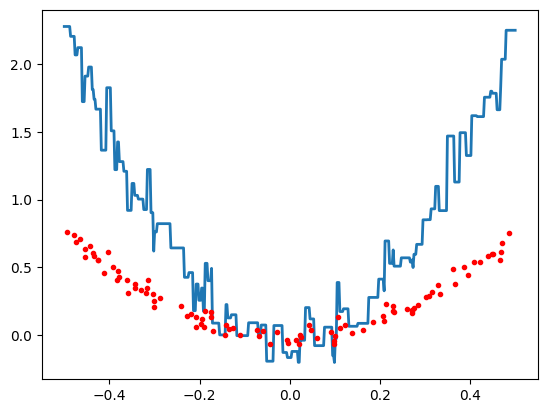

58


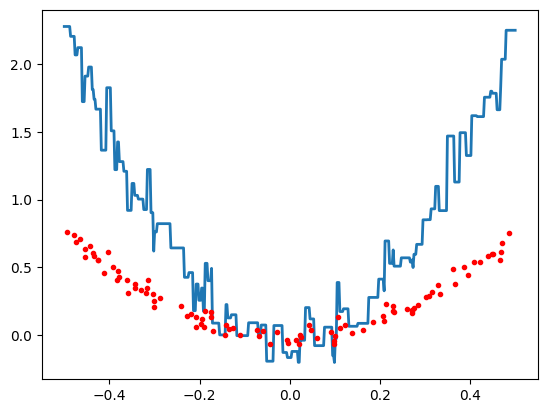

57


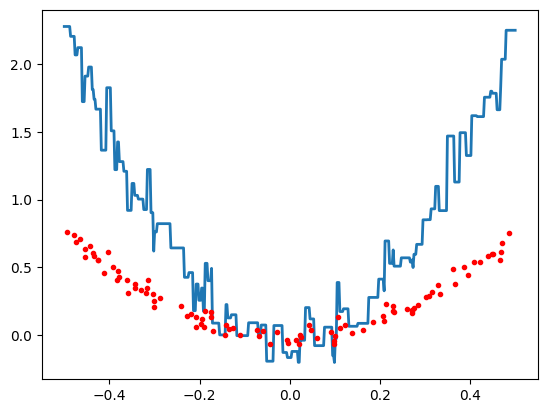

56


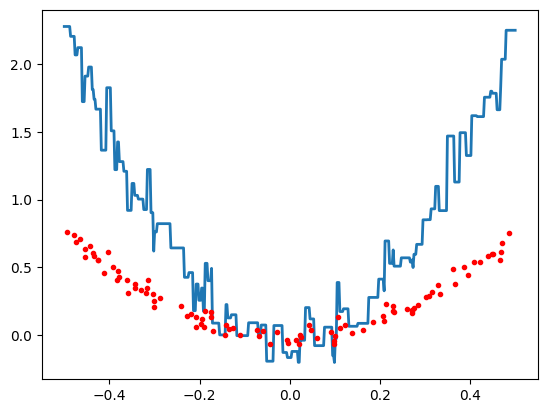

55


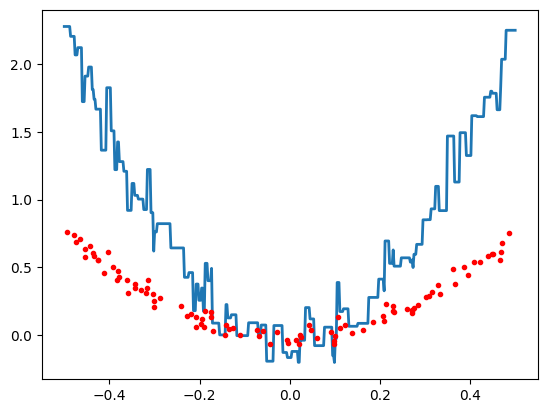

54


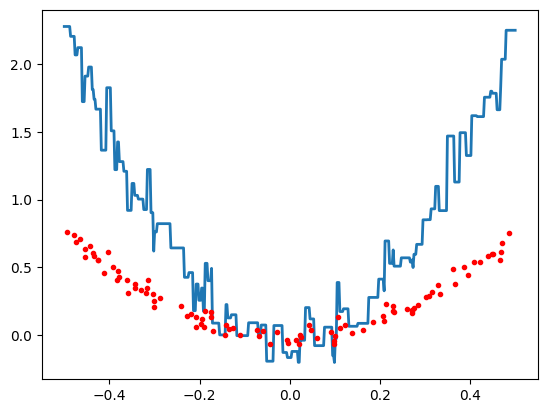

53


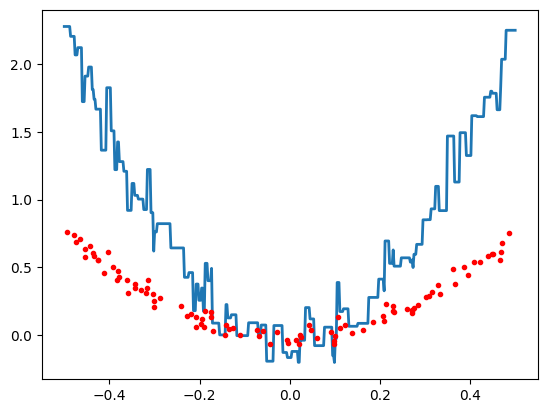

52


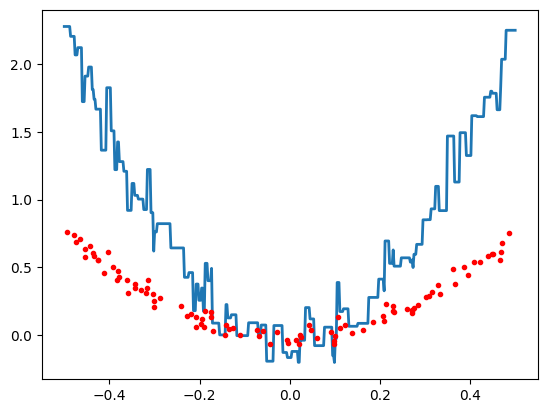

51


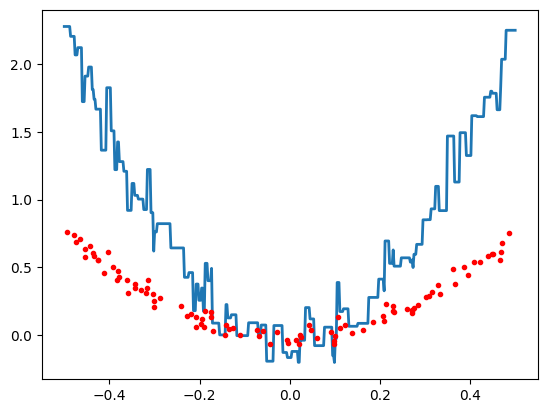

50


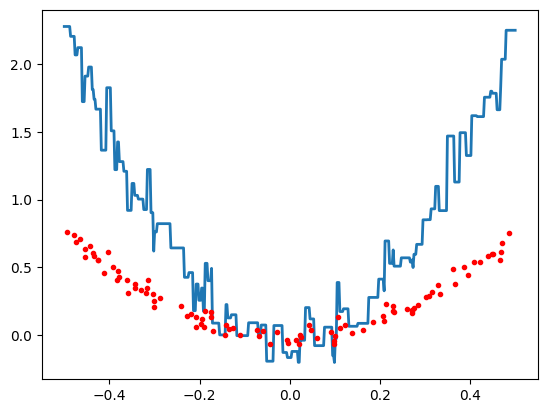

49


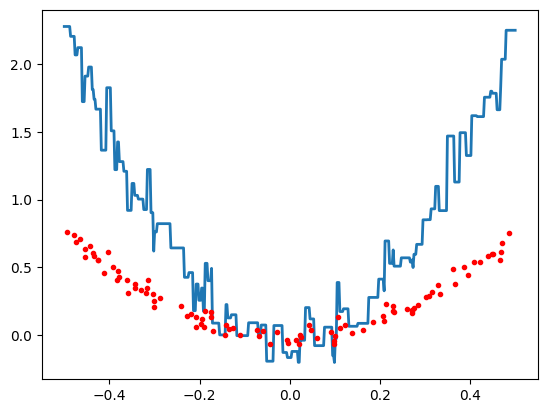

48


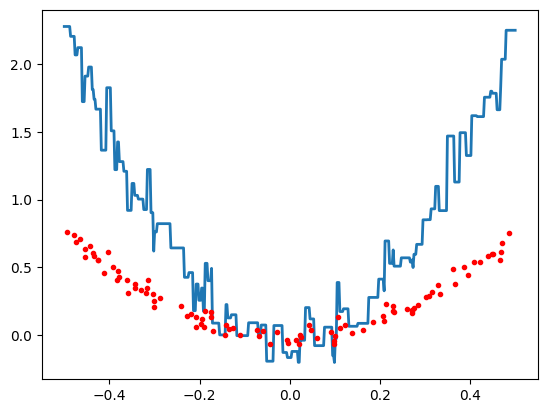

47


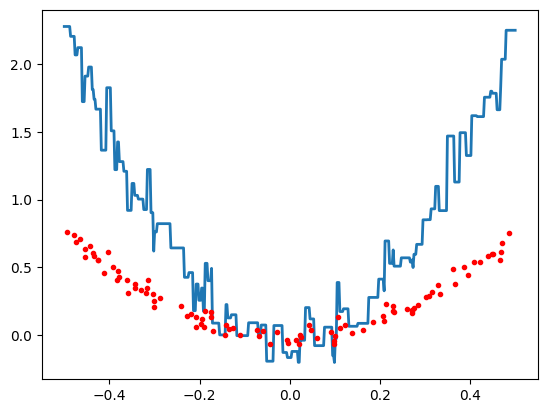

46


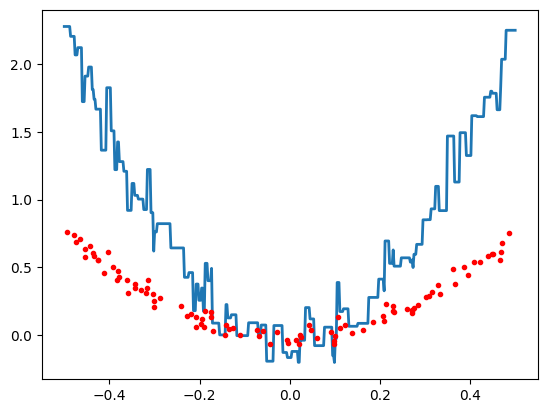

45


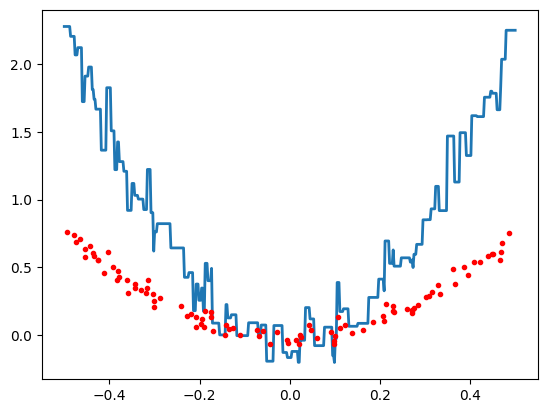

44


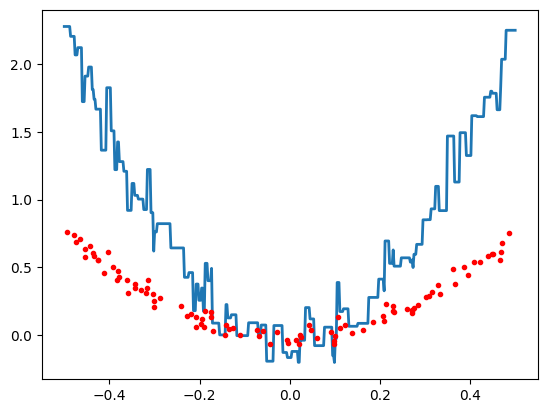

43


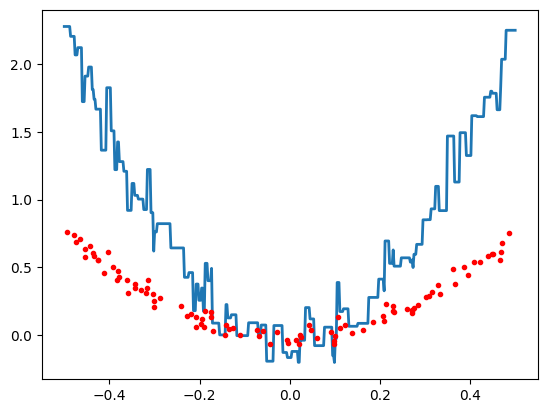

42


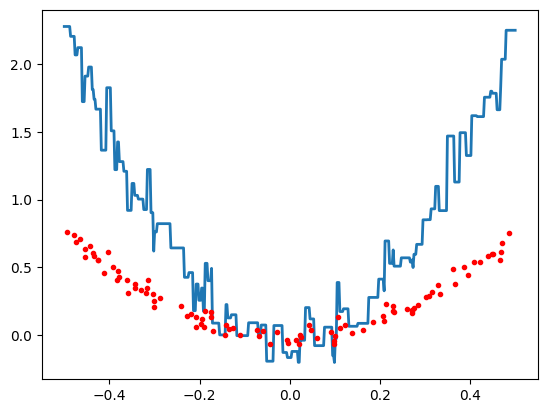

41


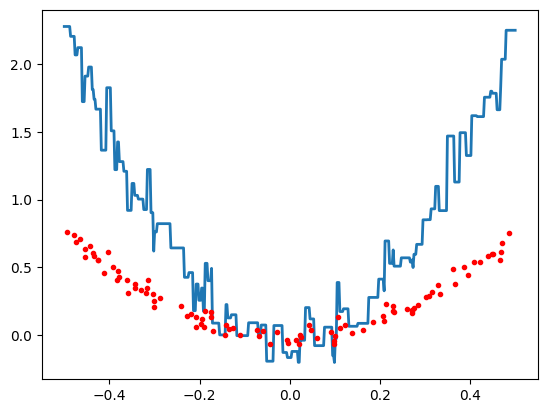

40


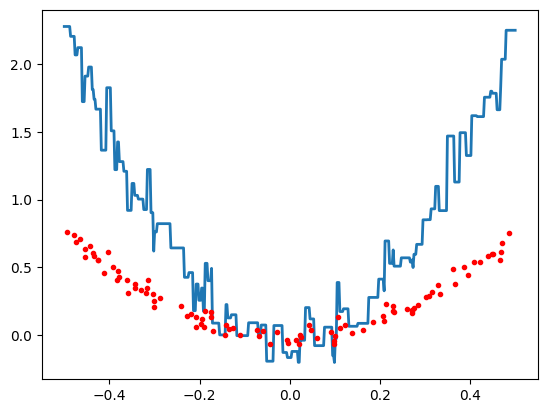

39


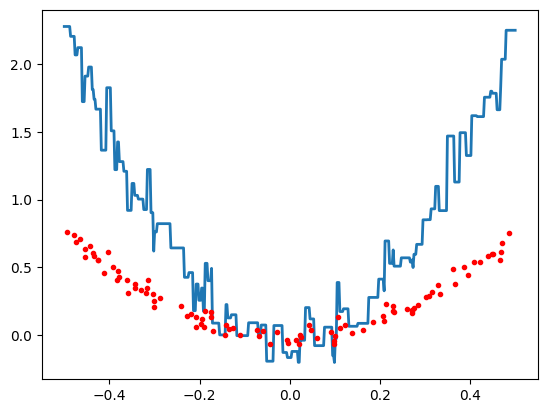

38


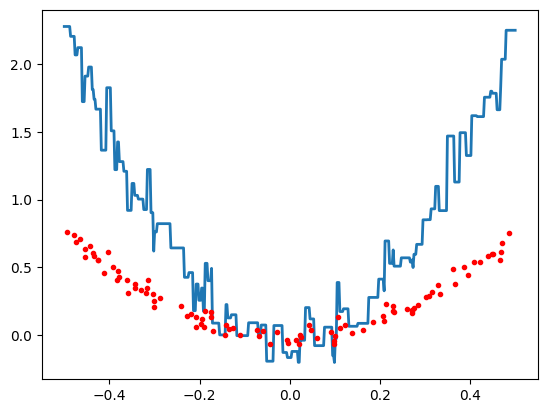

37


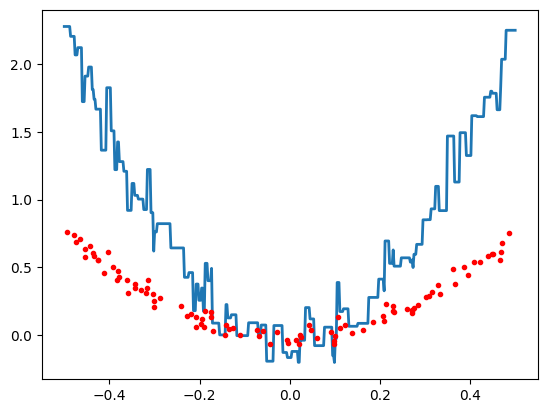

36


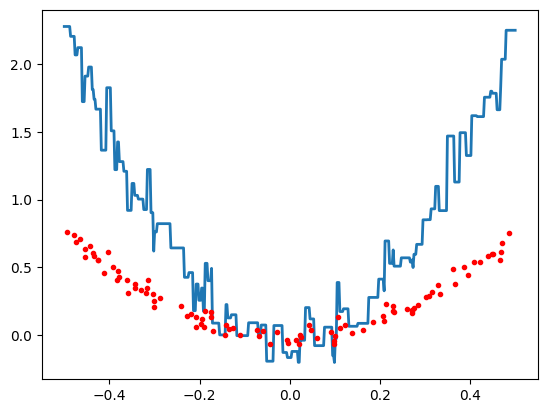

35


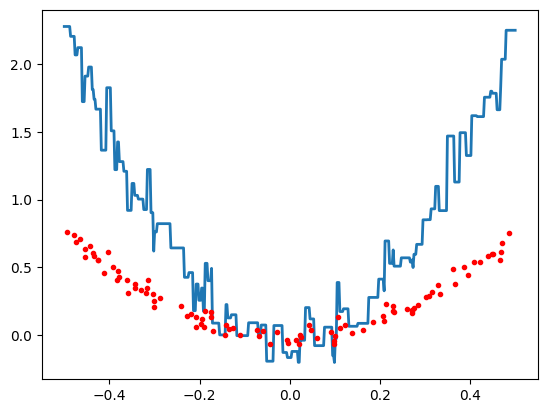

34


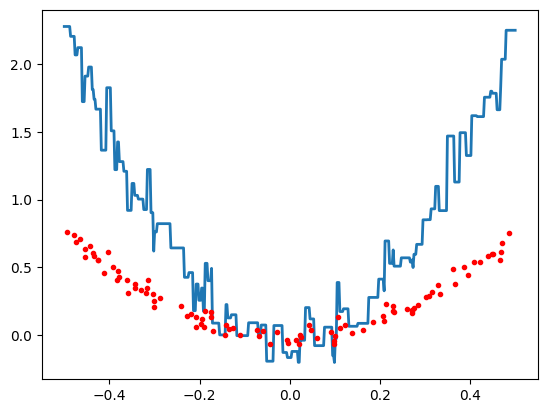

33


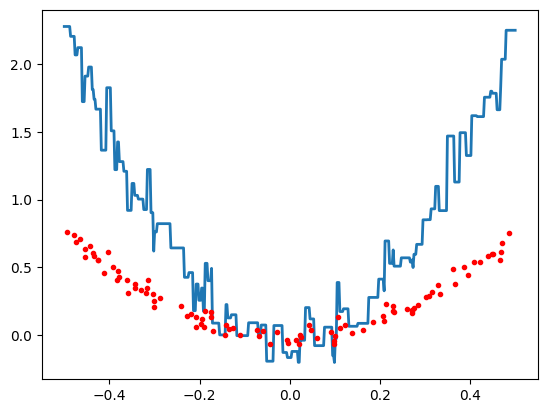

32


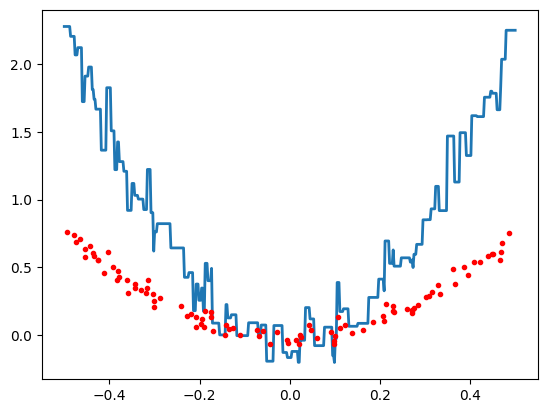

31


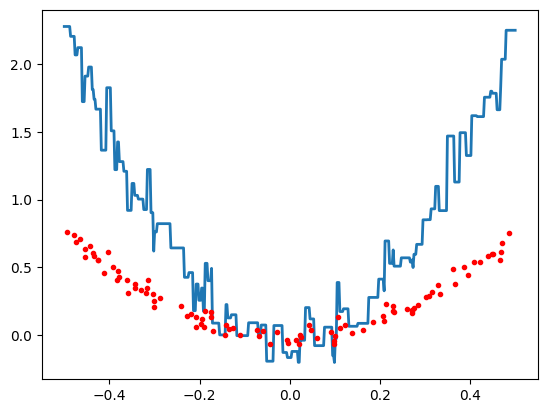

30


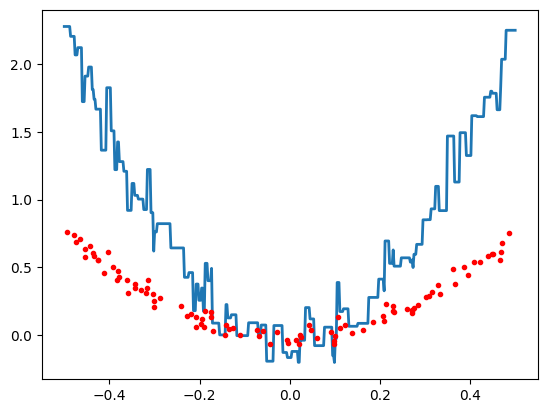

29


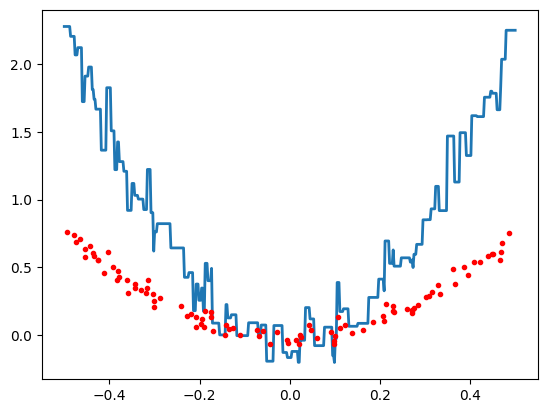

28


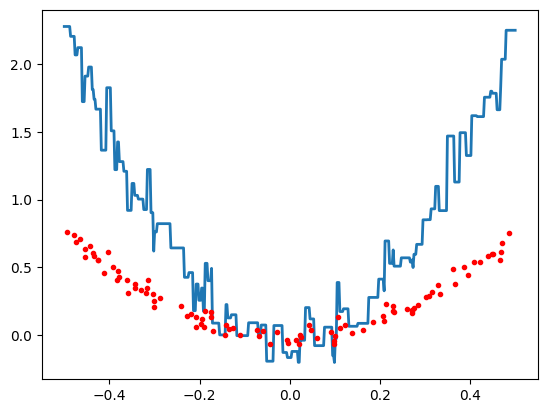

27


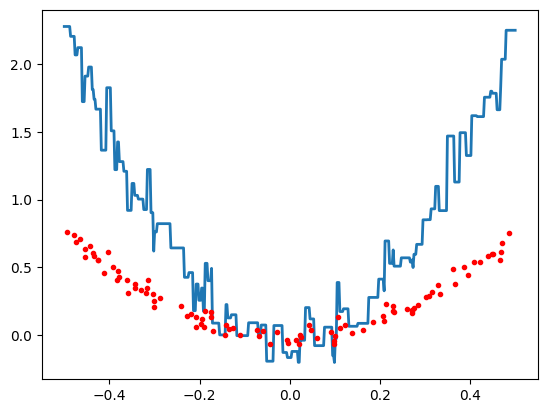

26


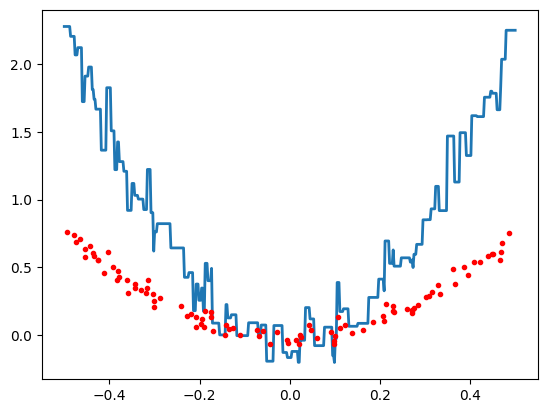

25


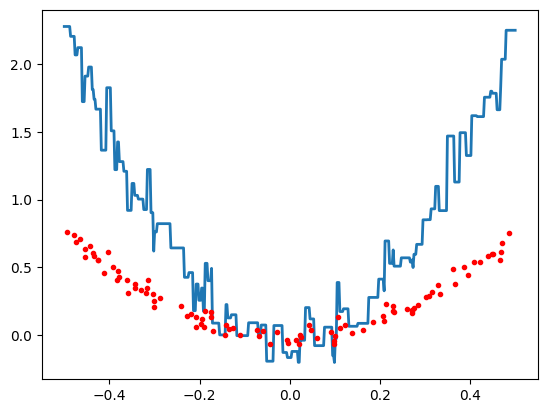

24


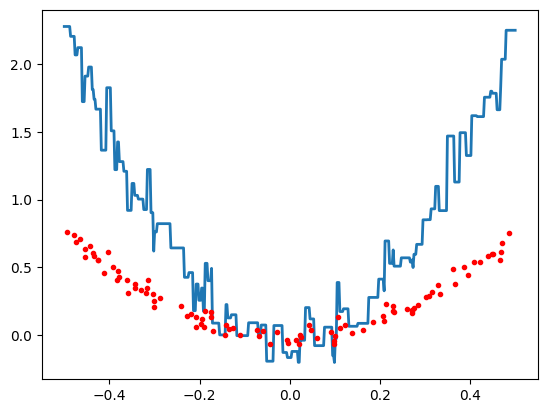

23


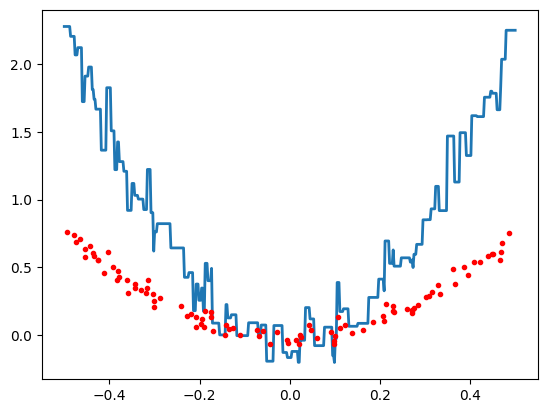

22


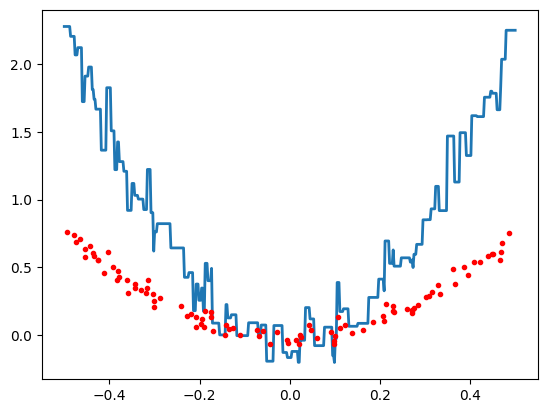

21


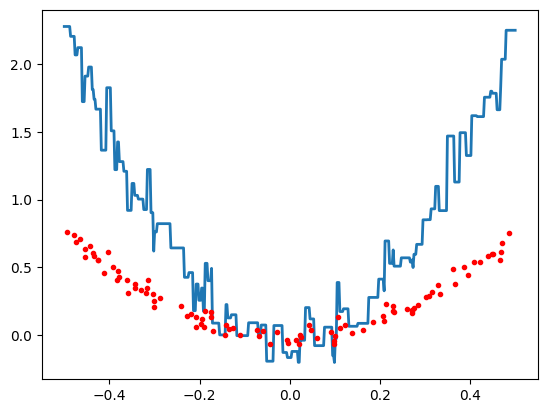

20


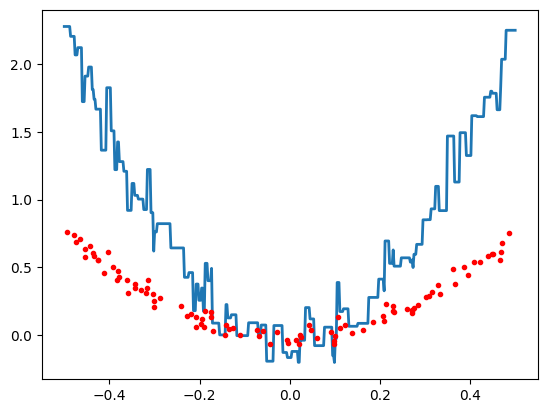

19


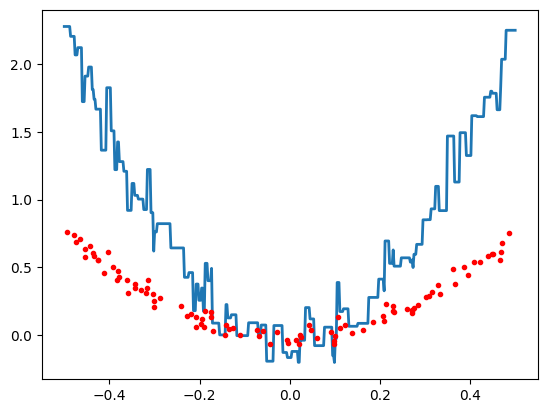

18


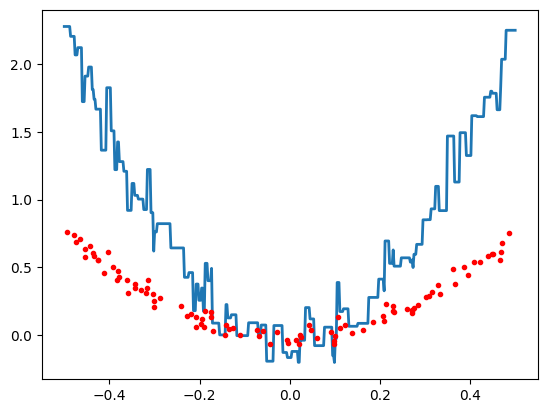

17


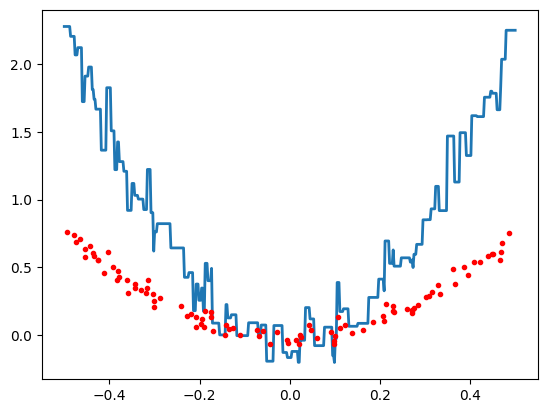

16


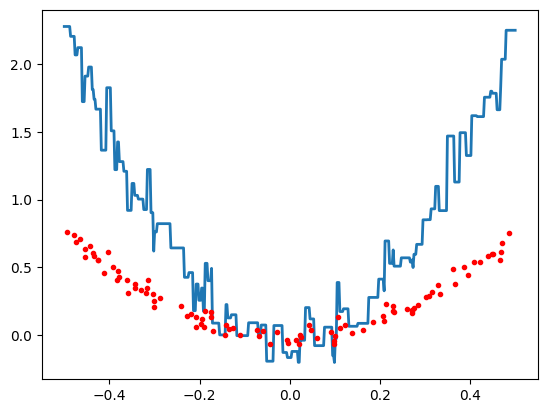

15


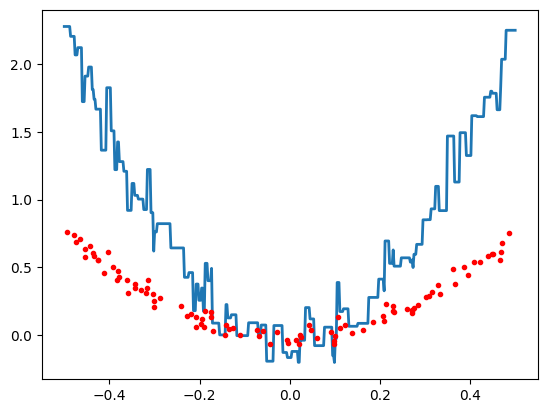

14


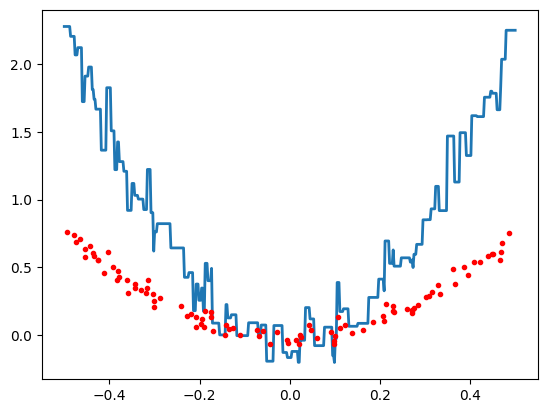

13


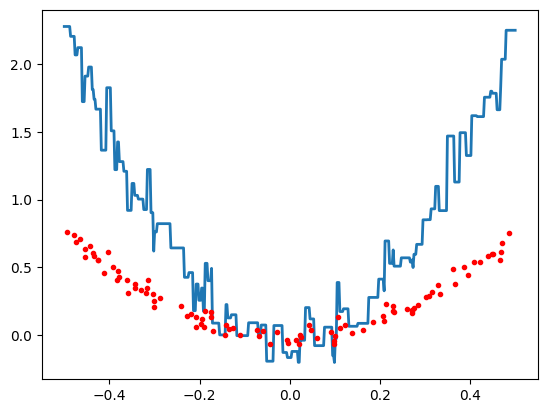

12


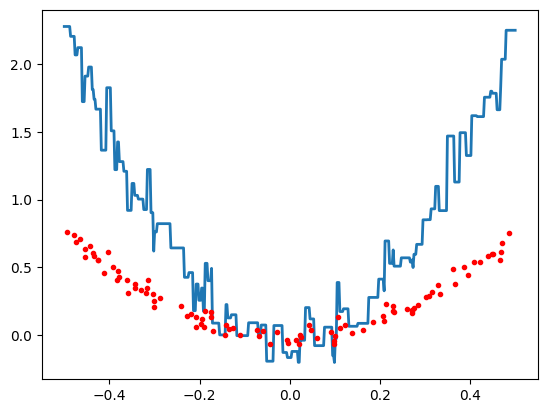

11


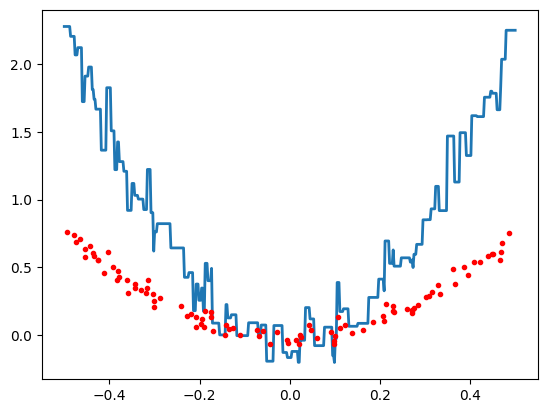

10


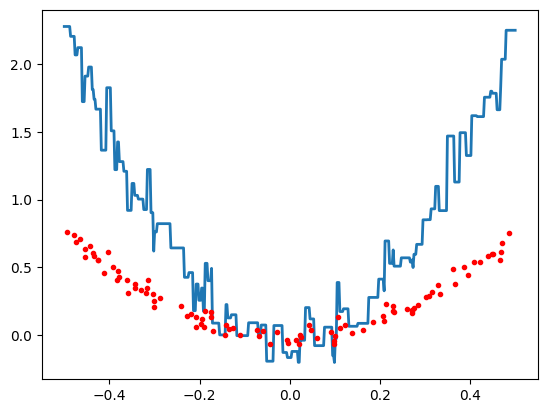

9


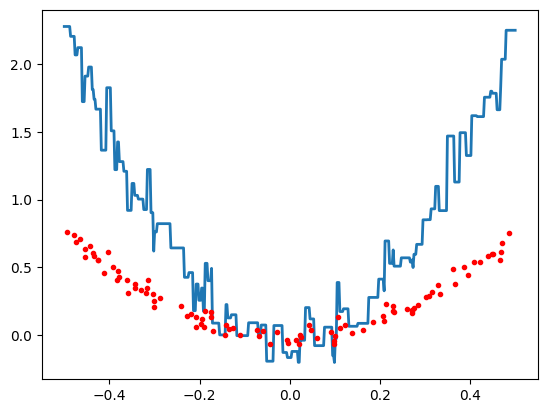

8


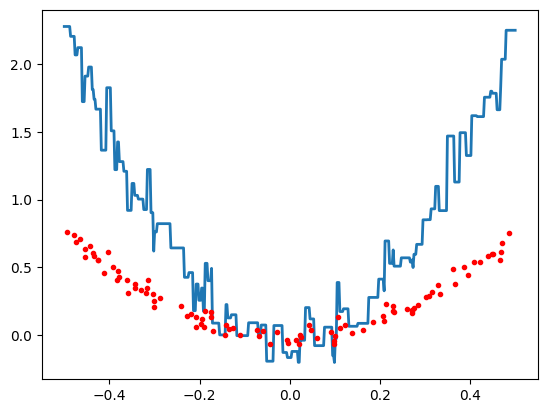

7


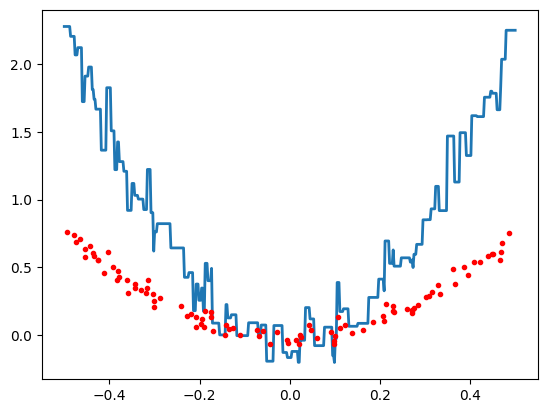

6


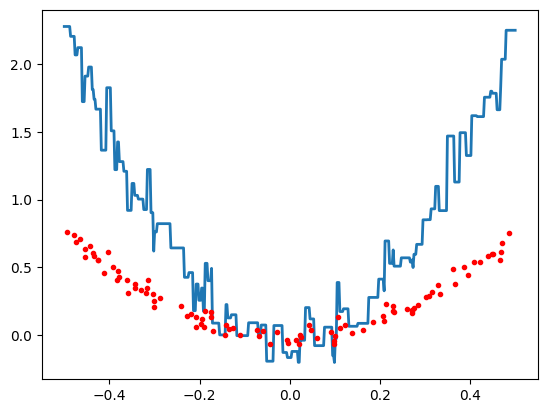

5


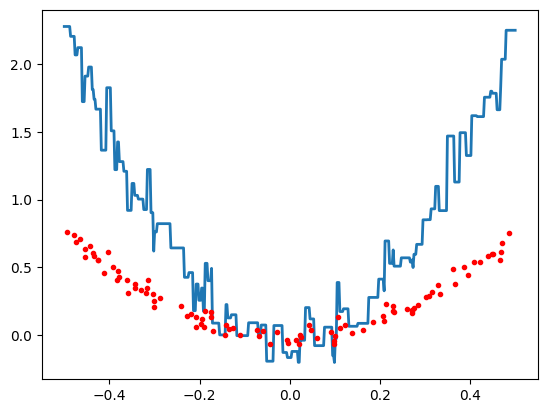

4


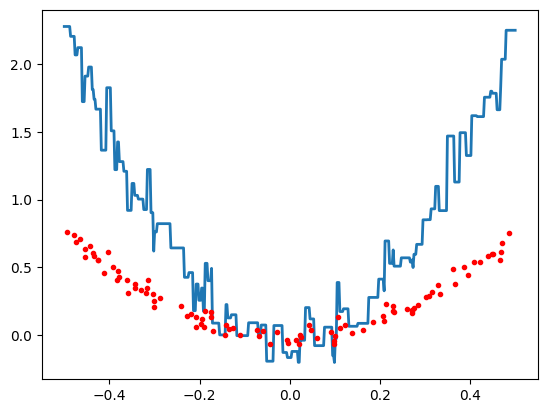

3


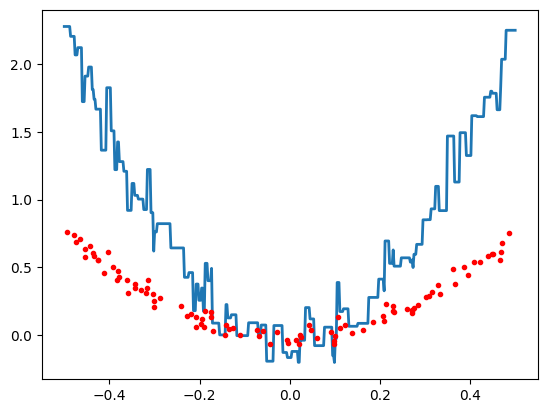

2


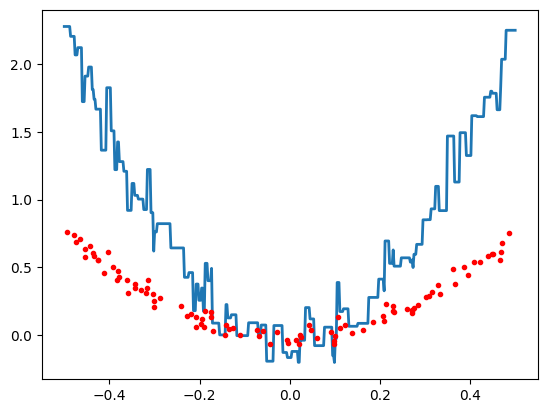

1


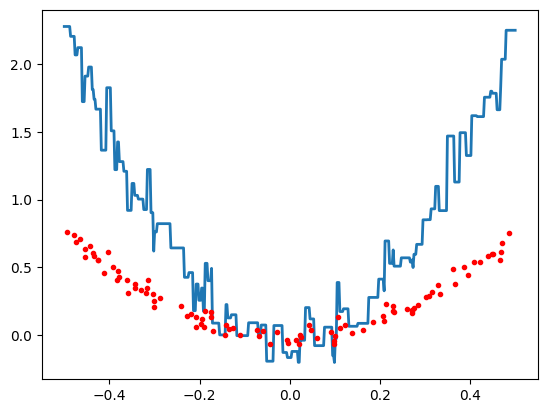

In [46]:
gradient_boost(X,y,100,lr=0.6)

10


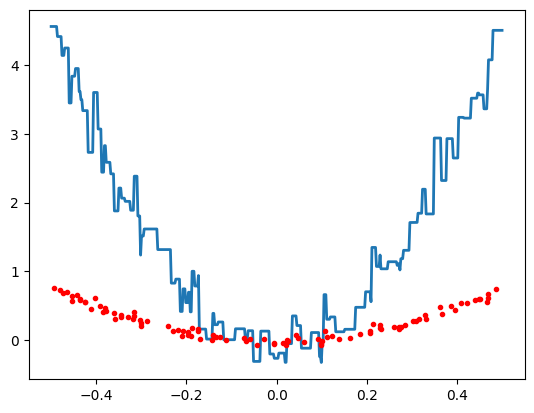

9


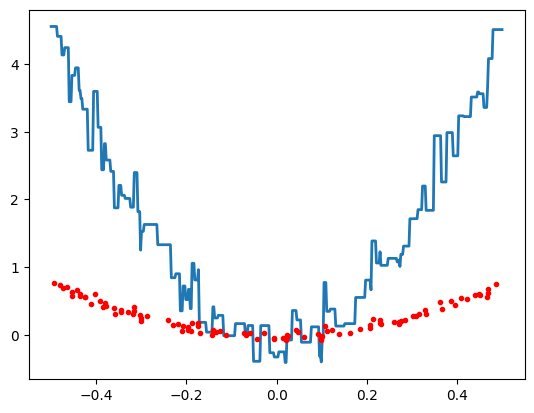

8


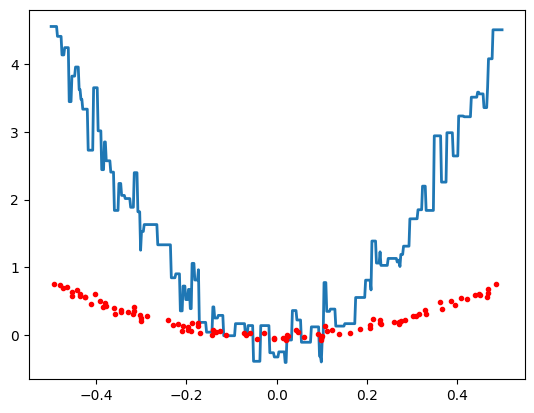

7


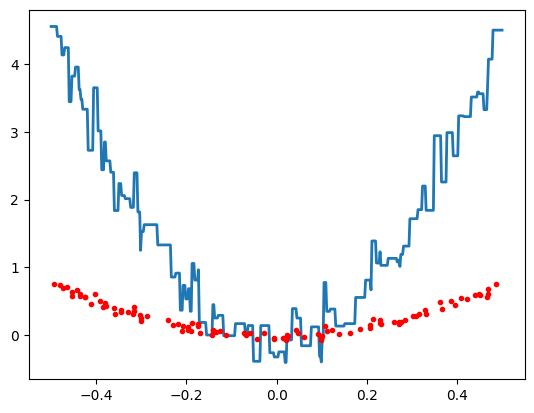

6


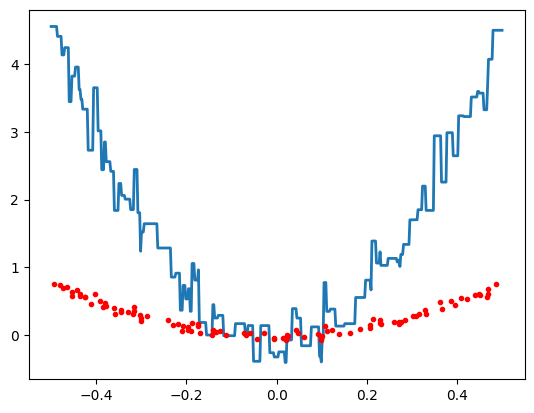

5


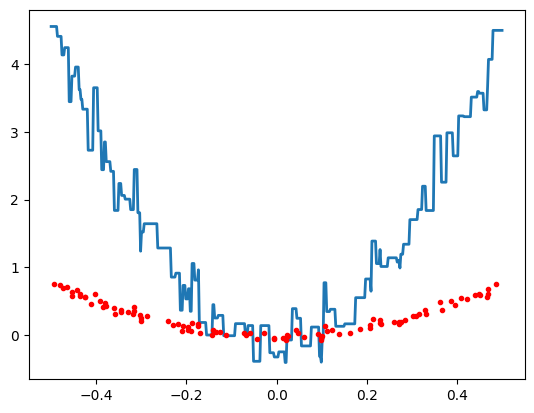

4


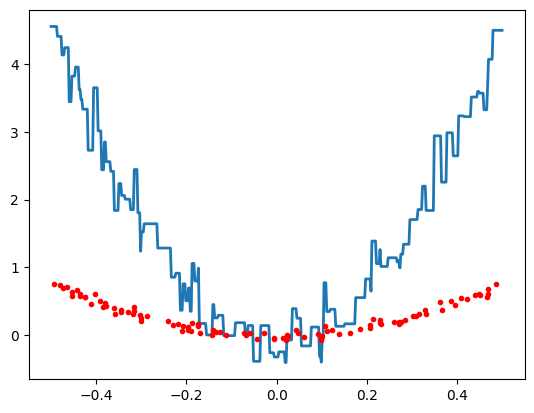

3


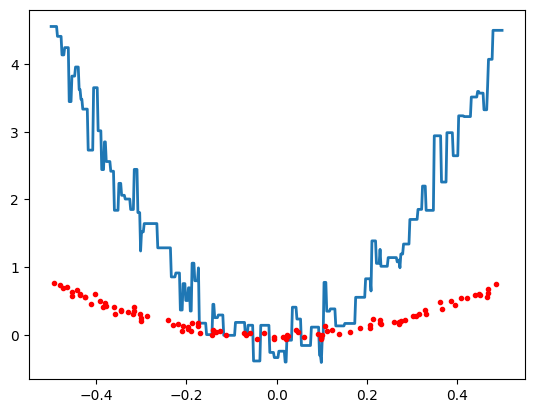

2


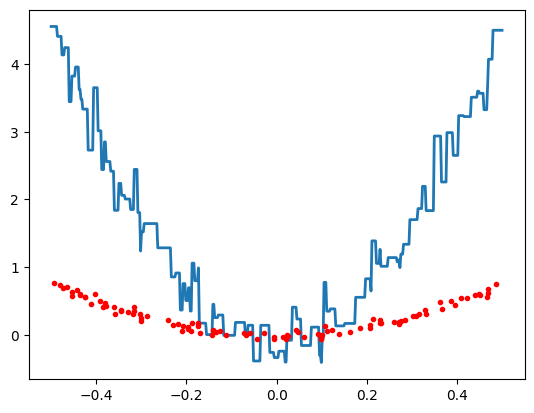

1


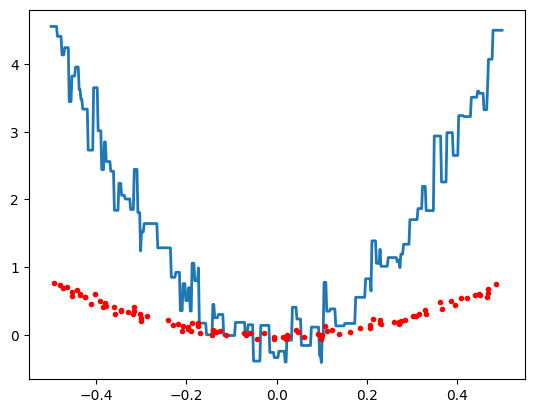

In [47]:
gradient_boost(X,y,10,lr=1)